# 02 — Baselines, metrics, and persisted results

**Goal:** load the embedding cache created in notebook 01, compare all reranking baselines on identical shortlists, and save per-query metrics, summary metrics, ranked candidates, and Seaborn darkgrid figures.

The `initial_clip` control reproduces the supplied candidate ordering from `clip_score`. `encoder_similarity` uses the selected encoder's own text–image cosine. MMR, adaptive MMR, DPP, and cluster-xQuAD share that encoder score as relevance input, so we can distinguish changing the representation from changing the ranking policy.

## 0. Initial Setup

In [1]:
from pathlib import Path
import sys
import pandas as pd
from IPython.display import display, Image

In [2]:
ROOT = Path.cwd()
if not (ROOT / "src" / "image_rerank").exists():
    ROOT = ROOT.parent
sys.path.insert(0, str(ROOT / "src"))

from image_rerank.experiment import load_cached_split, evaluate_queries
from image_rerank.plots import plot_tradeoff, plot_metric_bars
from image_rerank.artifacts import ensure_dir

SPLIT = "validation"
ENCODER_KEY = "openclip-ViT-B-32-openai"  # Must match notebook 01's encoder configuration.
MAX_QUERIES = None   # Use None once the full split has been cached.
OUTPUT_DIR = ROOT / "artifacts" / "experiments" / f"{SPLIT}_{ENCODER_KEY}_baseline"
RUN_NAME = f"{SPLIT}_{ENCODER_KEY}_baseline"

queries = load_cached_split(ROOT / "artifacts" / "cache", SPLIT, ENCODER_KEY)
if MAX_QUERIES is not None:
    queries = queries[:MAX_QUERIES]
print("Loaded cached query shortlists:", len(queries))
assert queries, "No embeddings found. Run notebook 01 first."

Loaded cached query shortlists: 40


## 1. Run the benchmark methods

AP@50 is the main candidate-list relevance metric. nDCG@10 and Recall@10 offer top-heavy relevance views. ILD@10 is the mean pairwise cosine distance among the ten returned images: it measures visual dispersion, not whether the variety is useful. Taxonomy coverage, when available, is a descriptive secondary metric.

In [3]:
metrics_df, summary_df = evaluate_queries(
    queries,
    top_k=50,
    diversity_k=10,
    output_dir=OUTPUT_DIR,
    run_name=RUN_NAME,
)

print("Per-query metrics:", metrics_df.shape)
print("Summary shape:", summary_df.shape)
display(summary_df.round(4))
display(metrics_df.head(10))

Per-query metrics: (240, 17)
Summary shape: (6, 21)


,method,rerank_latency_ms_mean,rerank_latency_ms_std,ap@50_mean,ap@50_std,ndcg@10_mean,ndcg@10_std,recall@10_mean,recall@10_std,ild@10_mean,...,unique_supercategory@10_mean,unique_supercategory@10_std,unique_category@10_mean,unique_category@10_std,unique_iconic_group@10_mean,unique_iconic_group@10_std,unique_inat24_species_name@10_mean,unique_inat24_species_name@10_std,rerank_latency_ms_p50,rerank_latency_ms_p95
0,adaptive_mmr,0.9911,0.4875,0.6140,0.1955,0.2849,0.2460,0.1271,0.1170,0.2017,...,1.0,0.0,1.0,0.0,1.0,0.0,4.100,2.1815,0.9161,1.1784
1,cluster_xquad,21.2580,2.2527,0.5653,0.2097,0.3256,0.2918,0.1471,0.1788,0.1511,...,1.0,0.0,1.0,0.0,1.0,0.0,3.575,2.1470,20.8984,25.6622
2,encoder_similarity,0.0254,0.0101,0.5650,0.2097,0.3313,0.2996,0.1482,0.1789,0.1455,...,1.0,0.0,1.0,0.0,1.0,0.0,3.450,2.1950,0.0225,0.0437
3,greedy_dpp,1.2192,0.2912,0.5832,0.1784,0.2873,0.2429,0.1228,0.1166,0.2051,...,1.0,0.0,1.0,0.0,1.0,0.0,3.950,2.0500,1.2412,1.6828
4,initial_clip,0.0323,0.0181,0.7077,0.1982,0.5140,0.3196,0.2465,0.1911,0.1807,...,1.0,0.0,1.0,0.0,1.0,0.0,3.150,1.8749,0.0270,0.0588
5,mmr_fixed_0.70,0.8885,0.2825,0.5666,0.2101,0.3340,0.2923,0.1514,0.1794,0.1520,...,1.0,0.0,1.0,0.0,1.0,0.0,3.450,2.1237,0.8499,1.2482


,query_id,query,method,rerank_latency_ms,ap@50,ndcg@10,recall@10,ild@10,unique_supercategory@10,unique_category@10,unique_iconic_group@10,unique_inat24_species_name@10,lambda_relevance,query_confidence,candidate_redundancy,top_score_gap_z,n_pseudo_aspects
0,26f08f48fba5,leopard on a road,initial_clip,0.0281,0.767442,1.000000,0.232558,0.158484,1,1,1,1,NaN,NaN,NaN,NaN,NaN
1,26f08f48fba5,leopard on a road,encoder_similarity,0.0440,0.697674,0.852171,0.186047,0.137560,1,1,1,2,NaN,NaN,NaN,NaN,NaN
2,26f08f48fba5,leopard on a road,mmr_fixed_0.70,1.0474,0.674419,0.845426,0.186047,0.137560,1,1,1,2,NaN,NaN,NaN,NaN,NaN
3,26f08f48fba5,leopard on a road,adaptive_mmr,1.9541,0.581395,0.702631,0.162791,0.293505,1,1,1,3,0.256616,0.070076,0.854750,0.072653,NaN
4,26f08f48fba5,leopard on a road,greedy_dpp,2.1826,0.534884,0.795166,0.186047,0.262988,1,1,1,3,NaN,NaN,NaN,NaN,NaN
5,26f08f48fba5,leopard on a road,cluster_xquad,25.3105,0.651163,0.852171,0.186047,0.137560,1,1,1,2,NaN,NaN,NaN,NaN,8.0
6,ccfab641388e,an immature bald eagle,initial_clip,0.0486,0.625000,0.485716,0.125000,0.150971,1,1,1,3,NaN,NaN,NaN,NaN,NaN
7,ccfab641388e,an immature bald eagle,encoder_similarity,0.0301,0.550000,0.602052,0.125000,0.138271,1,1,1,3,NaN,NaN,NaN,NaN,NaN
8,ccfab641388e,an immature bald eagle,mmr_fixed_0.70,0.9912,0.550000,0.554801,0.125000,0.138271,1,1,1,3,NaN,NaN,NaN,NaN,NaN
9,ccfab641388e,an immature bald eagle,adaptive_mmr,1.0997,0.600000,0.478902,0.100000,0.169049,1,1,1,3,0.262939,0.145306,0.863007,0.157011,NaN


## 2. Plot the trade-off and per-metric comparisons

Both plots use the repository's `sns.set_theme(style="darkgrid")`. Treat these as exploratory until the full validation split is evaluated.

Saved: d:\01 Work\14-research-Image-MMR\artifacts\experiments\validation_openclip-ViT-B-32-openai_baseline\figures\relevance_diversity_latency.png
Saved: d:\01 Work\14-research-Image-MMR\artifacts\experiments\validation_openclip-ViT-B-32-openai_baseline\figures\metric_comparison.png


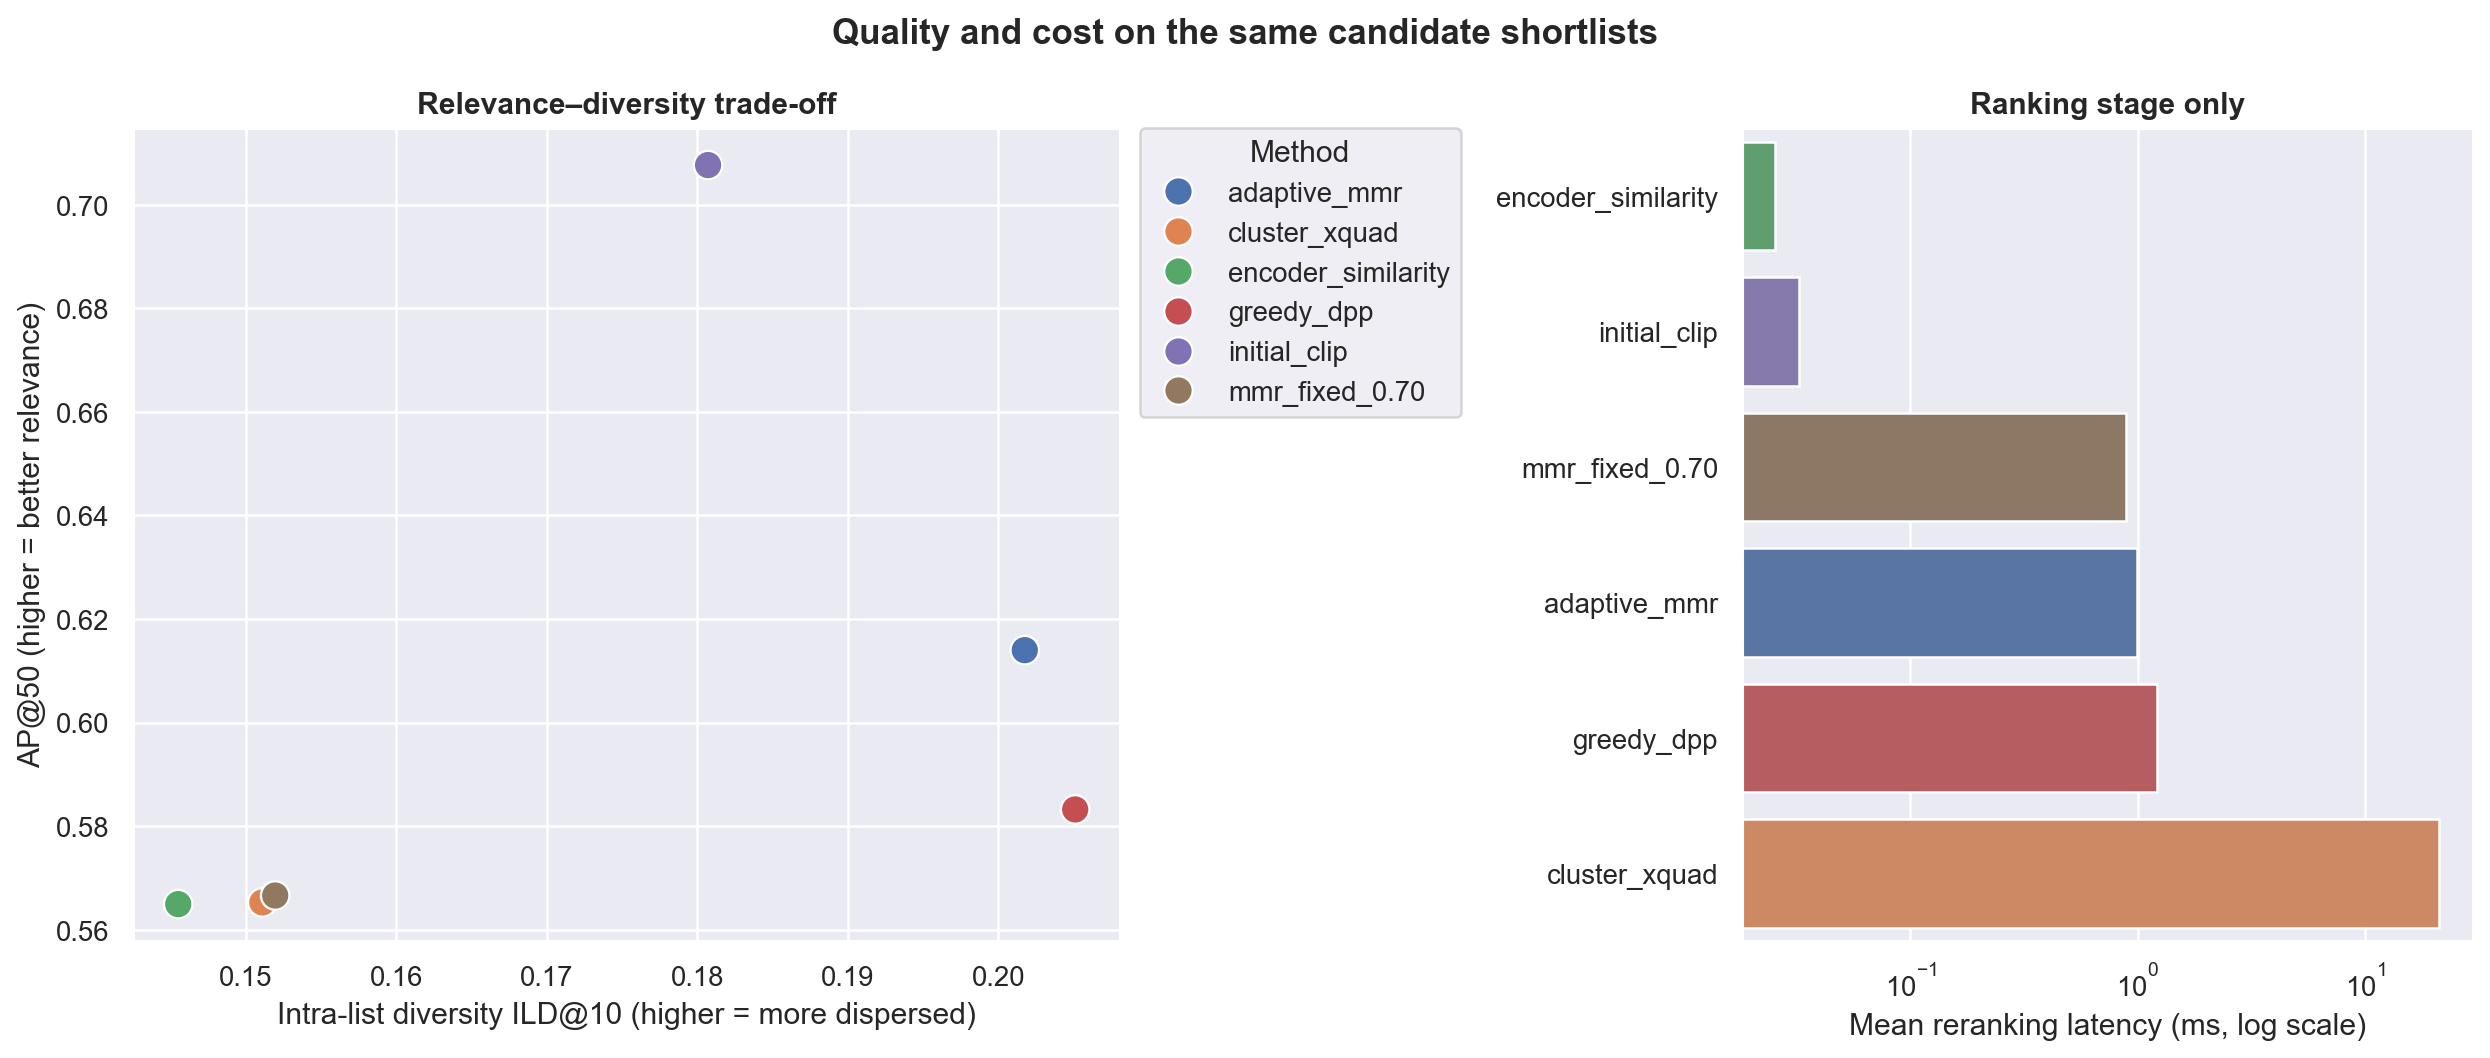

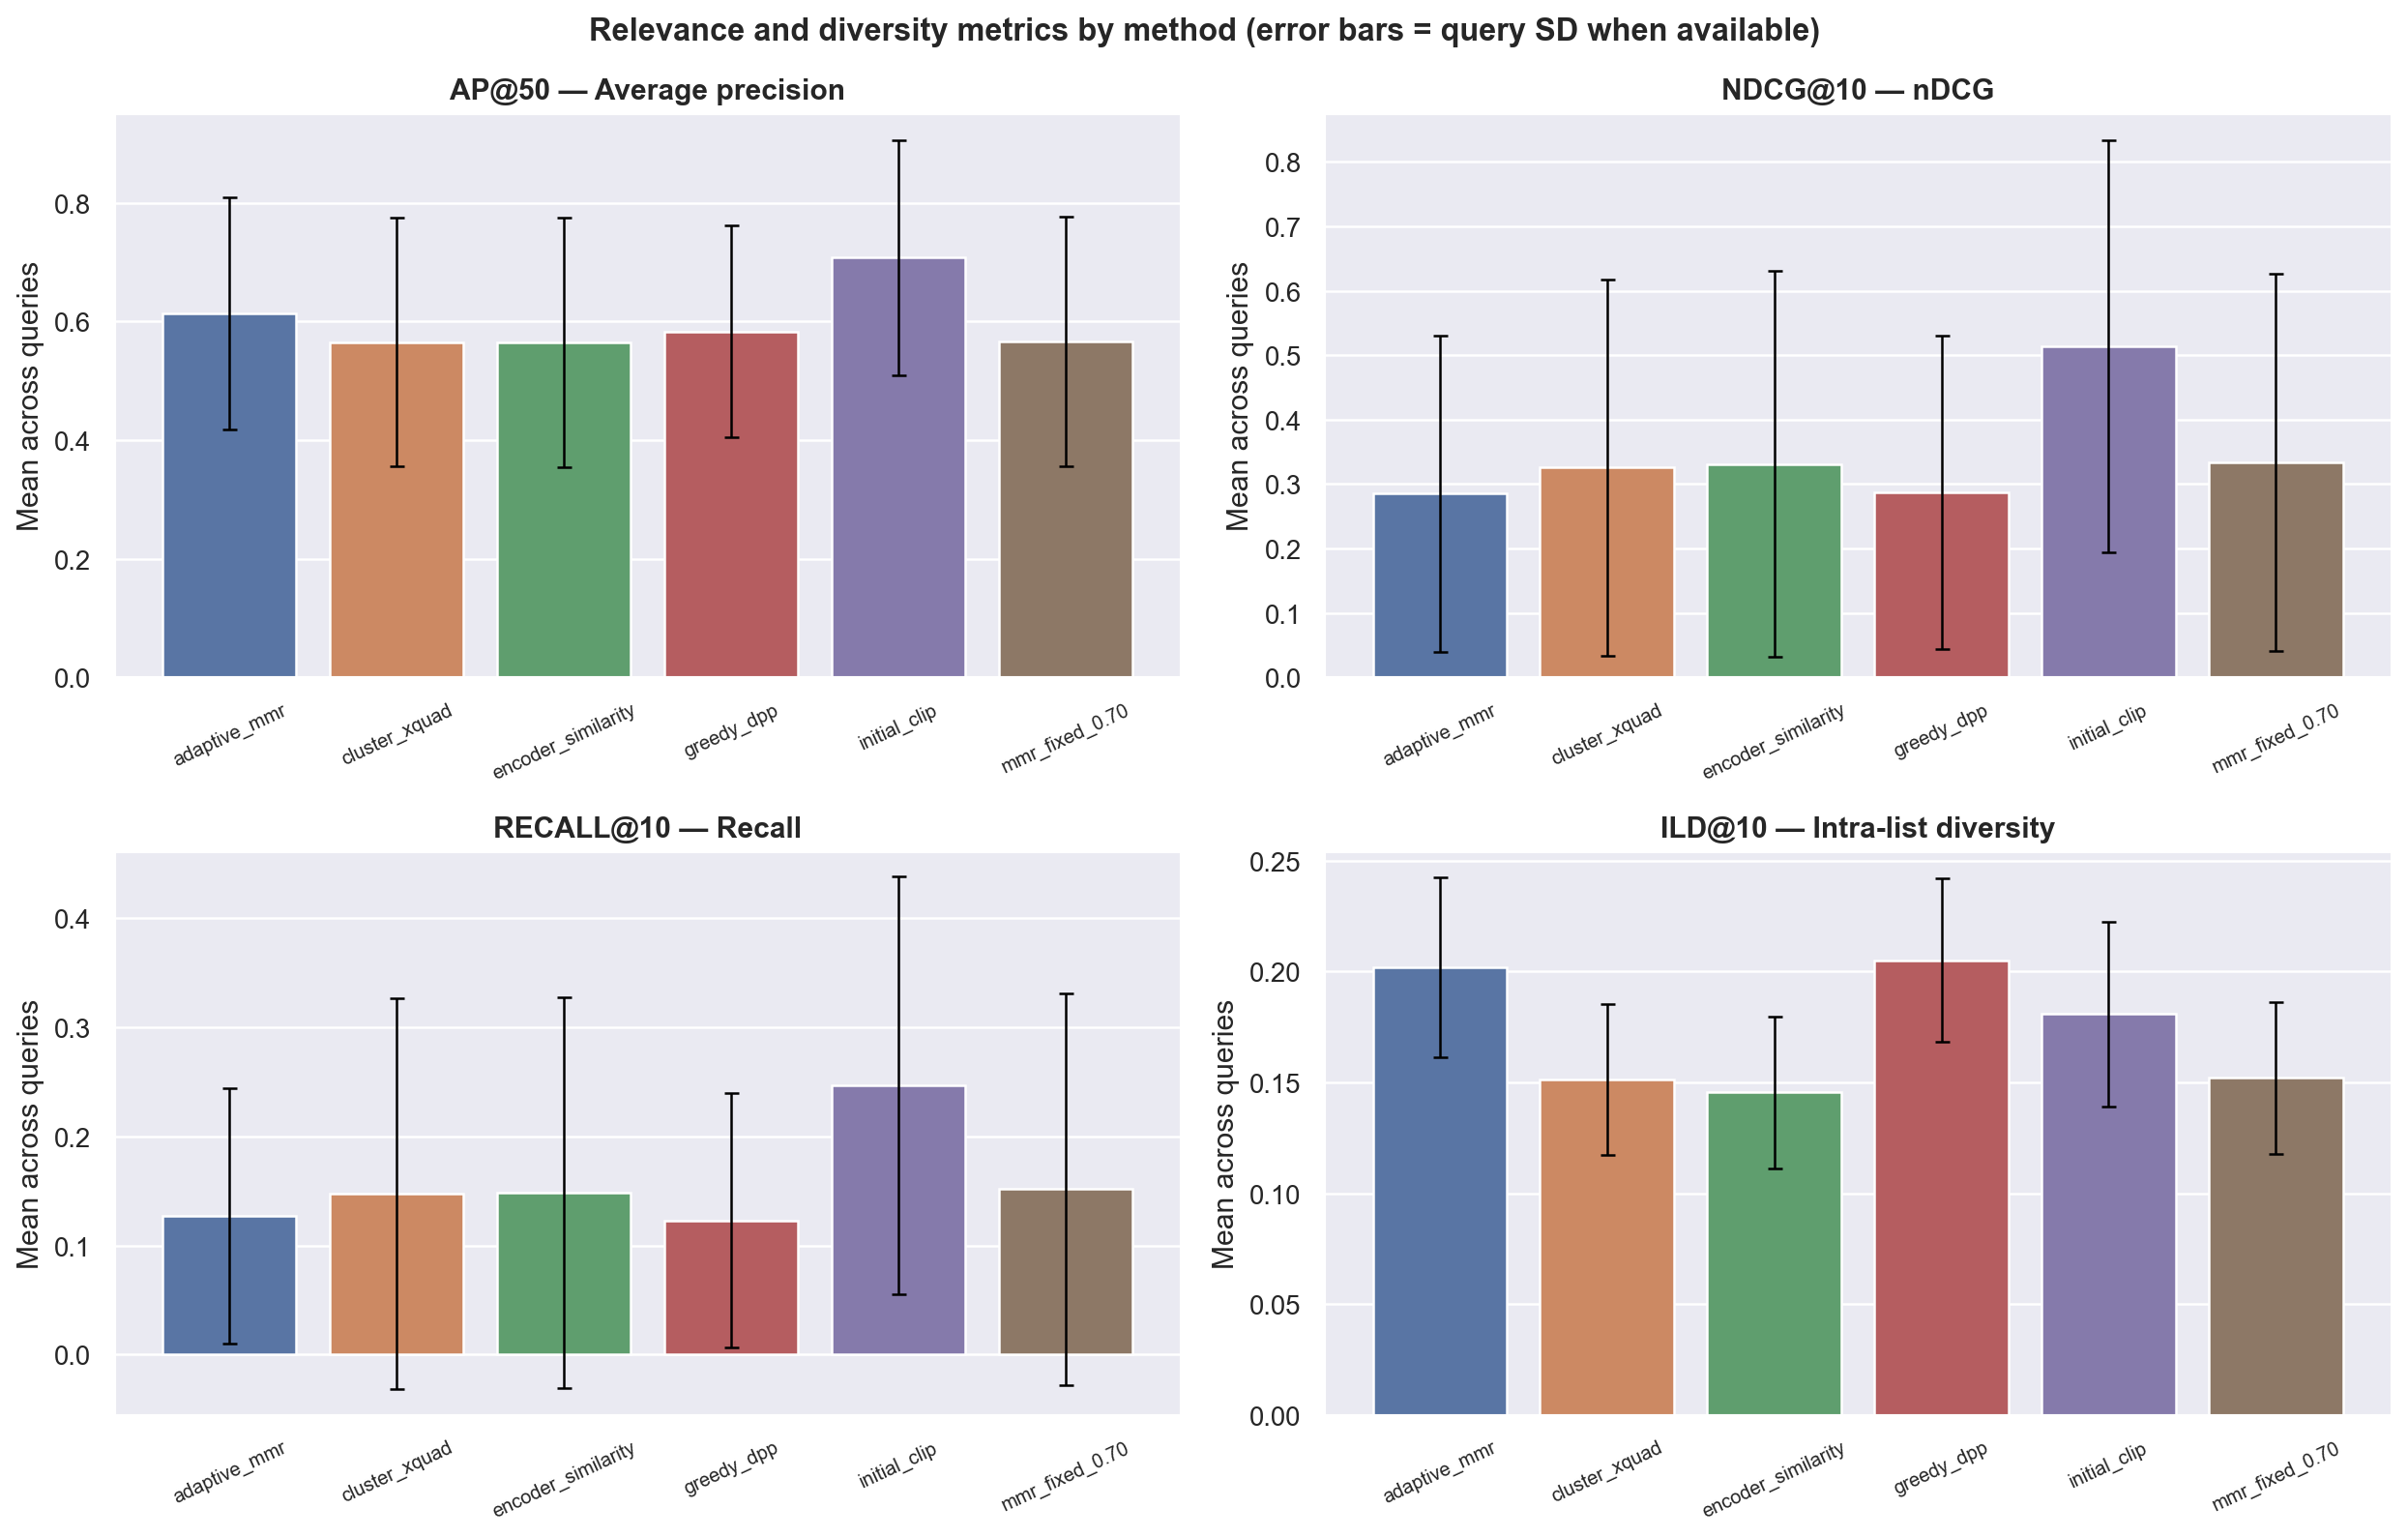

In [4]:
figure_dir = ensure_dir(OUTPUT_DIR / "figures")
tradeoff_path = plot_tradeoff(metrics_df, figure_dir / "relevance_diversity_latency.png")
metric_path = plot_metric_bars(summary_df, figure_dir / "metric_comparison.png")
print("Saved:", tradeoff_path)
print("Saved:", metric_path)
display(Image(filename=str(tradeoff_path)))
display(Image(filename=str(metric_path)))

## 3. Inspect saved rankings

The ranking CSV has one row per query, method, and candidate rank. It records the candidate image ID, original score, encoder similarity, and binary relevance label. This makes qualitative error analysis possible without re-running the encoder.

In [5]:
ranking_path = OUTPUT_DIR / "rankings" / f"{RUN_NAME}_rankings.csv"
rankings_df = pd.read_csv(ranking_path)
display(rankings_df.query("method == 'adaptive_mmr'").head(15))

print("Saved artifacts:")
for path in sorted(OUTPUT_DIR.rglob("*")):
    if path.is_file():
        print(path.relative_to(ROOT), f"({path.stat().st_size:,} bytes)")

,query_id,query,method,rank,image_id,initial_clip_score,encoder_similarity,relevant,metadata__supercategory,metadata__category,metadata__iconic_group,metadata__inat24_species_name
150,26f08f48fba5,leopard on a road,adaptive_mmr,1,1643630,0.361328,0.356633,1,Context,Human Impact,Mammals,Panthera pardus
151,26f08f48fba5,leopard on a road,adaptive_mmr,2,4490454,0.329834,0.318769,0,Context,Human Impact,Mammals,Canis aureus
152,26f08f48fba5,leopard on a road,adaptive_mmr,3,3680445,0.368652,0.354822,1,Context,Human Impact,Mammals,Panthera pardus
153,26f08f48fba5,leopard on a road,adaptive_mmr,4,1015478,0.358887,0.312299,1,Context,Human Impact,Mammals,Panthera pardus
154,26f08f48fba5,leopard on a road,adaptive_mmr,5,285987,0.334717,0.306223,0,Context,Human Impact,Mammals,Panthera pardus
155,26f08f48fba5,leopard on a road,adaptive_mmr,6,1065809,0.347656,0.327524,1,Context,Human Impact,Mammals,Panthera pardus
156,26f08f48fba5,leopard on a road,adaptive_mmr,7,2890443,0.346191,0.304943,0,Context,Human Impact,Mammals,Panthera onca
157,26f08f48fba5,leopard on a road,adaptive_mmr,8,2979998,0.374023,0.353818,1,Context,Human Impact,Mammals,Panthera pardus
158,26f08f48fba5,leopard on a road,adaptive_mmr,9,4124055,0.356934,0.337350,1,Context,Human Impact,Mammals,Panthera pardus
159,26f08f48fba5,leopard on a road,adaptive_mmr,10,4413300,0.348633,0.337048,1,Context,Human Impact,Mammals,Panthera pardus


Saved artifacts:
artifacts\experiments\validation_openclip-ViT-B-32-openai_baseline\figures\metric_comparison.png (170,155 bytes)
artifacts\experiments\validation_openclip-ViT-B-32-openai_baseline\figures\relevance_diversity_latency.png (148,938 bytes)
artifacts\experiments\validation_openclip-ViT-B-32-openai_baseline\metrics\validation_openclip-ViT-B-32-openai_baseline_per_query_metrics.csv (40,951 bytes)
artifacts\experiments\validation_openclip-ViT-B-32-openai_baseline\metrics\validation_openclip-ViT-B-32-openai_baseline_run_metadata.json (755 bytes)
artifacts\experiments\validation_openclip-ViT-B-32-openai_baseline\metrics\validation_openclip-ViT-B-32-openai_baseline_summary.csv (2,215 bytes)
artifacts\experiments\validation_openclip-ViT-B-32-openai_baseline\rankings\validation_openclip-ViT-B-32-openai_baseline_rankings.csv (2,044,097 bytes)


## 4. Interpretation checklist

### Does AP@50 fall when ILD@10 rises?


| Method | AP@50 ↑ | ILD@10 ↑ |
|---|---:|---:|
| Initial CLIP | **0.7077** | 0.1807 |
| Encoder Similarity | 0.5650 | 0.1455 |
| Fixed MMR | 0.5666 | 0.1520 |
| Adaptive MMR | 0.6140 | 0.2017 |
| Greedy DPP | 0.5832 | **0.2051** |
| Cluster xQuAD | 0.5653 | 0.1511 |

- Generally yes, but not consistently
- **Adaptive MMR** improves both AP@50 and ILD@10 over fixed MMR, but neither surpasses initial CLIP in relevance

### Is any diversity gain larger than query-to-query variation?

- Not established yet.
- Adaptive MMR increases ILD@10 from 0.1520 to 0.2017 compared with fixed MMR, an improvement of approximately 32.7%.
- However, the notebook does not provide ILD standard deviations or paired confidence intervals in its displayed summary.
- The improvement is promising, but paired bootstrap confidence intervals are required to determine whether it is statistically reliable

### Is cluster-xQuAD merely spreading across noisy clusters?

- Possibly, but the current results cannot confirm this.
- Cluster-xQuAD achieves:
    - AP@50: 0.5653
    - ILD@10: 0.1511
    - Mean latency: 21.258 ms
- Its diversity is nearly identical to fixed MMR (0.1520), despite substantially higher latency.
- Cluster-xQuAD provides little measurable benefit here; cluster coherence and relevance must be inspected before attributing this to noisy clusters.

### Does a latency reduction hold across queries, or is it a few outliers?

| Method | Mean (ms) | P50 (ms) | P95 (ms) |
|---|---:|---:|---:|
| Fixed MMR | 0.8885 | 0.8499 | 1.2482 |
| Adaptive MMR | 0.9911 | 0.9161 | 1.1784 |
| Greedy DPP | 1.2192 | 1.2412 | 1.6828 |
| Cluster xQuAD | 21.2580 | 20.8984 | 25.6622 |

- The latency differences appear consistent across queries
- Fixed MMR has the lowest mean reranking latency among diversity-aware methods, while adaptive MMR has a slightly better P95. Cluster-xQuAD is consistently much slower

## The End